# 15장 실습. 온도 스케일링과 보정 지표

12장에서 엔진·과제마다 온도 하나를 맞췄고, 14장의 파인튜닝은 질문 유형마다 온도를 맞춰 체크포인트에 넣었다. 이 노트북은 그 선택들을 따로 떼어 잰다.

| 절 | 내용 |
|---|---|
| 15.1 | 보정 지표 — ECE(같은 폭·같은 개수), MCE, Brier 분해 |
| 15.2 | 온도의 단위 — 하나·질문 유형별·과제별 |
| 15.3 | 라벨 몇 개면 되나 — 보정용 표본 수와 온도의 흔들림 |
| 15.4 | 체크포인트에 온도 쓰기 — `laya.calibrate` |
| 15.5 | 기권 임계값 — 목표 오류율에서 거꾸로 정하고, 상한으로 여유를 둔다 |

15.4 를 빼면 `results/eval_v1/` 의 기록만 읽는다. GPU 도 API 키도 필요 없다.

In [1]:
import os, json, time, random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests
import koreanize_matplotlib  # noqa: F401
from dotenv import load_dotenv
from requests.adapters import HTTPAdapter, Retry

load_dotenv()
DATA, OUT = Path("data"), Path("out")
OUT.mkdir(exist_ok=True)
TASKS = ["topic", "entails", "positive", "similarity"]
COLOR = {"topic": "#2a78d6", "entails": "#eb6834", "positive": "#1baf7a", "similarity": "#eda100"}
pd.set_option("display.precision", 3)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
read_jsonl = lambda p: [json.loads(l) for l in Path(p).read_text(encoding="utf-8").splitlines() if l.strip()]

assert (DATA / "eval_v1.jsonl").exists(), "평가셋이 없다. nb00_setup → nb08_evaluation 을 먼저 실행한다"

def probs_of(answer):
    return answer.get("probabilities") or {"true": answer["noul"], "false": 1 - answer["noul"]}

def judge(item, resp):
    (task, q), = item["questions"].items()
    a = resp["answers"][task]
    pr = {str(k): float(v) for k, v in probs_of(a).items()}
    best = max(pr, key=pr.get)
    pred = {"noul": lambda: pr["true"] >= 0.5, "choice": lambda: best, "score": lambda: int(best)}[q["type"]]()
    return {"id": item["id"], "task": item["task"], "qtype": q["type"], "gold": item["gold"], "model": resp["model"],
            "pred": pred, "probs": pr, "conf": pr[best], "conf_field": a.get("confidence"), "correct": bool(pred == item["gold"]),
            "input_tokens": resp["usage"]["input_tokens"], "latency_s": resp["_latency_s"]}

def run(items, engine=lambda it: ask(it["state"], it["questions"]), workers=4):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(lambda it: judge(it, engine(it)), items))

arrays = lambda recs: (np.array([r["conf"] for r in recs]), np.array([r["correct"] for r in recs], float))

def ece(conf, ok, bins=15):
    idx = np.clip(np.searchsorted(np.linspace(0, 1, bins + 1), conf, side="left") - 1, 0, bins - 1)
    return float(sum(abs(conf[idx == i].mean() - ok[idx == i].mean()) * (idx == i).sum() for i in np.unique(idx)) / len(conf))

from scipy.optimize import minimize_scalar
from scipy.special import log_softmax

RESULTS = Path("results/eval_v1")
recs = {p.name.replace(".records.jsonl", ""): read_jsonl(p) for p in sorted(RESULTS.glob("*.records.jsonl"))}
by_task = lambda rs, t: [r for r in rs if r["task"] == t]
print("기록이 있는 엔진:", list(recs))

기록이 있는 엔진: ['anyjev', 'jev', 'laya-ft-ddp-human', 'laya-ft-rlcd-human', 'laya-ft-rlcd-llm', 'laya-ft-rlcd-mix', 'laya-ft-softce-human', 'laya-routed', 'llm-gen', 'tfidf-baseline']


## 15.1 보정 지표: ECE·MCE·Brier 분해

8장의 ECE 는 확신을 같은 폭 15구간으로 나눈다. 확신이 0.9 이상에 몰린 엔진은 대부분 구간이 비고 큰 구간 하나가 값을 정한다. 같은 개수 구간(equal-mass)은 항목 수가 같도록 자르므로 이 문제가 덜하다. MCE 는 가장 크게 어긋난 구간 하나를 본다. Brier 점수는 reliability(보정 오차, 작을수록 좋다) − resolution(맞는 것과 틀린 것을 가르는 힘, 클수록 좋다) + uncertainty(과제의 어려움) 로 나뉜다.

In [2]:
def bins(conf, ok, n=15):
    idx = np.clip(np.searchsorted(np.linspace(0, 1, n + 1), conf, side="left") - 1, 0, n - 1)
    return [(conf[idx == i].mean(), ok[idx == i].mean(), (idx == i).sum()) for i in np.unique(idx)]

def ece_mass(conf, ok, n=15):
    chunks = np.array_split(np.argsort(conf, kind="stable"), n)
    return sum(len(c) * abs(conf[c].mean() - ok[c].mean()) for c in chunks) / len(conf)

mce = lambda conf, ok: max(abs(c - y) for c, y, _ in bins(conf, ok))

def brier_parts(conf, ok):
    rows, base = bins(conf, ok, 10), ok.mean()
    return {"reliability": sum(n * (c - y) ** 2 for c, y, n in rows) / len(conf), "resolution": sum(n * (y - base) ** 2 for _, y, n in rows) / len(conf),
            "uncertainty": base * (1 - base), "brier": np.mean((conf - ok) ** 2)}

metrics = lambda conf, ok: {"정확도": ok.mean(), "ECE (같은 폭)": ece(conf, ok), "ECE (같은 개수)": ece_mass(conf, ok), "MCE": mce(conf, ok), **brier_parts(conf, ok)}
pd.DataFrame([{"과제": t, "엔진": n, **metrics(*arrays(by_task(rs, t)))} for n, rs in recs.items() for t in TASKS]).set_index(["과제", "엔진"]).sort_index()

정확도  ECE (같은 폭)  ECE (같은 개수)    MCE  \
과제         엔진                                                            
entails    anyjev                0.940       0.079        0.076  0.315   
           jev                   0.975       0.061        0.056  0.510   
           laya-ft-ddp-human     0.875       0.056        0.077  0.063   
           laya-ft-rlcd-human    0.870       0.069        0.080  0.514   
           laya-ft-rlcd-llm      0.885       0.077        0.081  0.166   
           laya-ft-rlcd-mix      0.890       0.036        0.051  0.473   
           laya-ft-softce-human  0.895       0.098        0.098  0.190   
           laya-routed           0.880       0.110        0.094  0.483   
           llm-gen               0.910       0.089        0.089  0.089   
           tfidf-baseline        0.675       0.045        0.073  0.082   
positive   anyjev                0.790       0.097        0.093  0.272   
           jev                   0.850       0.036        0.053  0.112   
           laya-ft-ddp-human     0.785       0.080        0.110  0.526   
           laya-ft-rlcd-human    0.775       0.078        0.097  0.373   
           laya-ft-rlcd-llm      0.795       0.063        0.080  0.147   
           laya-ft-rlcd-mix      0.800       0.079        0.096  0.163   
           laya-ft-softce-human  0.800       0.060        0.079  0.418   
           laya-routed           0.665       0.146        0.162  0.235   
           llm-gen               0.780       0.189        0.190  0.189   
           tfidf-baseline        0.820       0.037        0.062  0.139   
similarity anyjev                0.250       0.225        0.222  0.439   
           jev                   0.350       0.275        0.277  0.465   
           laya-ft-ddp-human     0.525       0.127        0.127  0.748   
           laya-ft-rlcd-human    0.470       0.072        0.137  0.769   
           laya-ft-rlcd-llm      0.310       0.121        0.137  0.608   
           laya-ft-rlcd-mix      0.480       0.094        0.122  0.854   
           laya-ft-softce-human  0.470       0.062        0.089  0.297   
           laya-routed           0.140       0.188        0.190  0.831   
           llm-gen               0.310       0.626        0.626  0.800   
           tfidf-baseline        0.305       0.239        0.245  0.622   
topic      anyjev                0.765       0.120        0.119  0.399   
           jev                   0.800       0.102        0.104  0.430   
           laya-ft-ddp-human     0.735       0.087        0.122  0.264   
           laya-ft-rlcd-human    0.745       0.063        0.079  0.128   
           laya-ft-rlcd-llm      0.670       0.059        0.129  0.207   
           laya-ft-rlcd-mix      0.745       0.089        0.083  0.321   
           laya-ft-softce-human  0.745       0.087        0.066  0.676   
           laya-routed           0.340       0.323        0.323  0.551   
           llm-gen               0.755       0.193        0.198  0.193   
           tfidf-baseline        0.815       0.122        0.128  0.496   

                                 reliability  resolution  uncertainty  brier  
과제         엔진                                                                 
entails    anyjev                  7.361e-03       0.011        0.056  0.053  
           jev                     5.866e-03       0.009        0.024  0.022  
           laya-ft-ddp-human       3.234e-03       0.016        0.109  0.096  
           laya-ft-rlcd-human      6.489e-03       0.026        0.113  0.092  
           laya-ft-rlcd-llm        7.733e-03       0.010        0.102  0.096  
           laya-ft-rlcd-mix        1.784e-03       0.012        0.098  0.087  
           laya-ft-softce-human    1.119e-02       0.013        0.094  0.091  
           laya-routed             1.281e-02       0.006        0.106  0.111  
           llm-gen                 7.877e-03       0.000        0.082  0.090  
           tfidf-baseline          1.960e-03       0.012 

## 15.2 온도 단위 비교

온도를 몇 개 둘지 정해야 한다. 적으면 과제마다 다른 과신을 한 숫자로 덮고, 많으면 온도 하나가 기대는 라벨이 줄어든다. 셋을 비교한다. 모두 반씩 나눠 한쪽에서 맞추고 다른 쪽에서 잰다(cross-fit, 12.4절).

| 단위 | 온도 수 | Laya 에서는 |
|---|---|---|
| 하나 | 1 | — |
| 질문 유형별 | 3 (choice·score·noul) | `temperature` (14장 파인튜닝이 맞춘 것) |
| 과제별 | 4 | — (12장에서 쓴 방식) |

이 평가셋에서는 noul 두 과제(entails·positive)만 같은 유형을 나눠 쓴다. 그래서 질문 유형별과 과제별의 차이는 이 두 과제에서만 생긴다. Laya 의 `temperature_by_options`((유형, 선택지 수)별)도 이 평가셋에서는 질문 유형별과 같다.

In [3]:
gold_key = lambda r: {"noul": lambda: ["false", "true"][r["gold"]], "choice": lambda: r["gold"], "score": lambda: str(r["gold"])}[r["qtype"]]()
logp = lambda r: np.log(np.clip(list(r["probs"].values()), 1e-6, 1))

def fit_temperature(rs):
    rows = [(logp(r), list(r["probs"]).index(gold_key(r))) for r in rs]
    return minimize_scalar(lambda T: -np.mean([log_softmax(lp / T)[g] for lp, g in rows]), bounds=(0.05, 20.0), method="bounded").x

apply_temperature = lambda rs, T: [r | {"conf": float(np.exp(log_softmax(logp(r) / T)).max())} for r in rs]

def cross_fit(rs, seed=0):
    idx = np.random.default_rng(seed).permutation(len(rs))
    a, b_ = [rs[i] for i in idx[: len(rs) // 2]], [rs[i] for i in idx[len(rs) // 2:]]
    return apply_temperature(a, fit_temperature(b_)) + apply_temperature(b_, fit_temperature(a))

def coverage_at_risk(conf, ok, risk=0.05):
    order = np.argsort(-conf, kind="stable")
    c, y, k = conf[order], ok[order], np.arange(1, len(conf) + 1)
    return float(np.max(k[np.append(c[1:] != c[:-1], True) & (np.cumsum(1 - y) / k <= risk)], initial=0) / len(conf))

UNITS = {"하나": lambda r: "all", "질문 유형별": lambda r: r["qtype"], "과제별": lambda r: r["task"]}
cross_fit_by = lambda rs, key: [x for g in sorted({key(r) for r in rs}) for x in cross_fit([r for r in rs if key(r) == g])]
rows = []
for n, rs in recs.items():
    for unit, key in UNITS.items():
        out = cross_fit_by(rs, key)
        rows.append({"엔진": n, "단위": unit, **{t: ece(*arrays(by_task(out, t))) for t in TASKS},
                     "평균 ECE": np.mean([ece(*arrays(by_task(out, t))) for t in TASKS]),
                     "평균 처리율@5%": np.mean([coverage_at_risk(*arrays(by_task(out, t))) for t in TASKS])})
pd.DataFrame(rows).set_index(["엔진", "단위"])

topic  entails  positive  similarity  평균 ECE  \
엔진                   단위                                                     
anyjev               하나      0.069    0.143     0.059       0.144   0.103   
                     질문 유형별  0.059    0.096     0.071       0.071   0.074   
                     과제별     0.059    0.044     0.048       0.071   0.056   
jev                  하나      0.064    0.177     0.133       0.143   0.129   
                     질문 유형별  0.056    0.030     0.044       0.055   0.046   
                     과제별     0.056    0.014     0.050       0.055   0.044   
laya-ft-ddp-human    하나      0.062    0.044     0.084       0.123   0.078   
                     질문 유형별  0.093    0.057     0.077       0.125   0.088   
                     과제별     0.093    0.028     0.047       0.125   0.073   
laya-ft-rlcd-human   하나      0.052    0.061     0.090       0.060   0.066   
                     질문 유형별  0.049    0.071     0.083       0.072   0.069   
                     과제별     0.049    0.041     0.066       0.072   0.057   
laya-ft-rlcd-llm     하나      0.059    0.105     0.020       0.106   0.073   
                     질문 유형별  0.067    0.076     0.057       0.036   0.059   
                     과제별     0.067    0.070     0.060       0.036   0.058   
laya-ft-rlcd-mix     하나      0.100    0.042     0.045       0.059   0.061   
                     질문 유형별  0.091    0.053     0.057       0.090   0.073   
                     과제별     0.091    0.037     0.055       0.090   0.068   
laya-ft-softce-human 하나      0.061    0.082     0.094       0.076   0.078   
                     질문 유형별  0.066    0.089     0.082       0.089   0.081   
                     과제별     0.066    0.035     0.078       0.089   0.067   
laya-routed          하나      0.060    0.045     0.051       0.087   0.061   
                     질문 유형별  0.056    0.037     0.056       0.045   0.048   
                     과제별     0.056    0.055     0.064       0.045   0.055   
llm-gen              하나      0.342    0.067     0.033       0.162   0.151   
                     질문 유형별  0.002    0.036     0.042       0.070   0.037   
                     과제별     0.002    0.005     0.019       0.070   0.024   
tfidf-baseline       하나      0.185    0.071     0.053       0.204   0.128   
                     질문 유형별  0.105    0.027     0.028       0.135   0.074   
                     과제별     0.105    0.059     0.059       0.135   0.089   

                             평균 처리율@5%  
엔진                   단위                 
anyjev               하나          0.389  
                     질문 유형별      0.340  
                     과제별         0.354  
jev                  하나          0.552  
                     질문 유형별      0.566  
                     과제별         0.556  
laya-ft-ddp-human    하나          0.239  
                     질문 유형별      0.282  
                     과제별         0.214  
laya-ft-rlcd-human   하나          0.280  
                     질문 유형별      0.255  
                     과제별         0.217  
laya-ft-rlcd-llm     하나          0.193  
                     질문 유형별      0.220  
                     과제별         0.184  
laya-ft-rlcd-mix     하나          0.300  
                     질문 유형별      0.321  
                     과제별         0.278  
laya-ft-softce-human 하나          0.323  
                     질문 유형별      0.310  
                     과제별         0.324  
laya-routed          하나          0.150  
                     질문 유형별      0.133  
                     과제별         0.143  
llm-gen              하나          0.106  
                     질문 유형별      0.106  
                     과제별         0.106  
tfidf-baseline       하나          0.199  
                     질문 유형별      0.212  
                     과제별         0.183

## 15.3 보정 표본 수

AnyJev 는 레이블 100~500건이면 된다고 밝혔다. 보정용 표본 수 n 을 바꿔 가며 온도를 맞추고, 나머지 항목에서 ECE 를 잰다. n 마다 200번 반복해 온도와 ECE 의 흔들림을 본다. 과제마다 200건뿐이라 n 은 100 까지 본다.

In [4]:
def sample_size_curve(rs, ns=(10, 25, 50, 100), reps=200, seed=0):
    rng = np.random.default_rng(seed)
    perms = [(n, rng.permutation(len(rs))) for n in ns for _ in range(reps)]
    return pd.DataFrame([{"n": n, "T": (T := fit_temperature([rs[i] for i in p[:n]])), "ECE": ece(*arrays(apply_temperature([rs[i] for i in p[n:]], T)))}
                         for n, p in perms])

curves = {(n, t): sample_size_curve(by_task(rs, t)) for n, rs in recs.items() for t in ["topic", "positive"]}
pd.concat({k: d.groupby("n").agg(T_중앙값=("T", "median"), T_사분위폭=("T", lambda s: s.quantile(.75) - s.quantile(.25)),
                                ECE_중앙값=("ECE", "median"), ECE_90분위=("ECE", lambda s: s.quantile(.9))) for k, d in curves.items()}, names=["엔진", "과제"])

T_중앙값  T_사분위폭  ECE_중앙값  ECE_90분위
엔진             과제       n                                    
anyjev         topic    10   1.461   0.660    0.097     0.170
                        25   1.415   0.351    0.090     0.133
                        50   1.425   0.265    0.082     0.124
                        100  1.429   0.140    0.096     0.133
               positive 10   1.648   1.821    0.087     0.216
...                            ...     ...      ...       ...
tfidf-baseline topic    100  0.753   0.096    0.121     0.153
               positive 10   1.001   0.970    0.079     0.183
                        25   1.006   0.630    0.061     0.116
                        50   1.047   0.403    0.059     0.097
                        100  1.060   0.242    0.071     0.101

[80 rows x 4 columns]

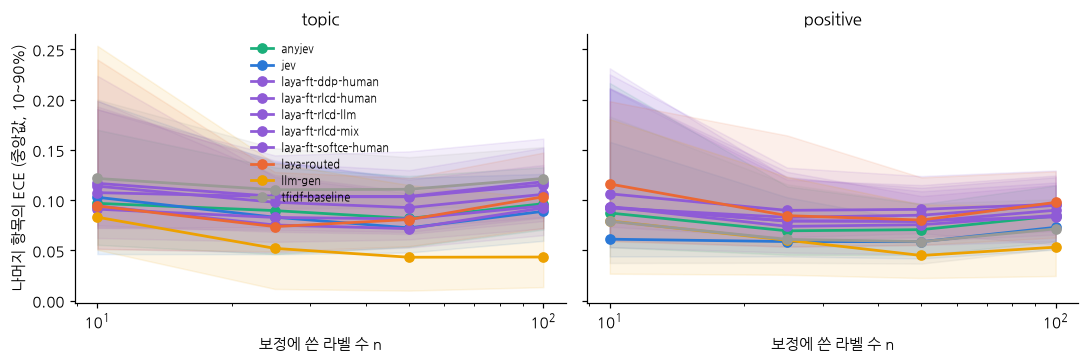

In [5]:
PALETTE = {"jev": "#2a78d6", "tfidf-baseline": "#9a9a96", "laya-routed": "#eb6834", "anyjev": "#1baf7a", "llm-gen": "#eda100"}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), dpi=110, sharey=True)
for ax, t in zip(axes, ["topic", "positive"]):
    for n in recs:
        g = curves[(n, t)].groupby("n")["ECE"]
        color = PALETTE.get(n, "#8f5bd6")
        ax.plot(g.median().index, g.median(), marker="o", color=color, lw=1.8, label=n)
        ax.fill_between(g.median().index, g.quantile(.1), g.quantile(.9), color=color, alpha=0.1)
    ax.set_xscale("log"); ax.set_title(t, fontsize=11); ax.set_xlabel("보정에 쓴 라벨 수 n")
axes[0].set_ylabel("나머지 항목의 ECE (중앙값, 10~90%)"); axes[0].legend(frameon=False, fontsize=7)
fig.tight_layout(); fig.savefig(OUT / "nb15_calibration_samples.png", bbox_inches="tight"); plt.show()

## 15.4 체크포인트 온도 저장

기록으로 맞춘 온도는 기록을 읽는 쪽에서만 쓴다. laya-serve 가 내는 확률에 바로 반영하려면 체크포인트 설정에 들어가야 한다. Laya 는 로짓에서 직접 온도를 맞추는 도구를 준다.

1. `records_from_labeled(agent, pairs)` — (state, 질문, 정답 분포)마다 로짓을 뽑는다
2. `agent.fit_temperatures(records)` — 질문 유형별 온도와 (유형, 선택지 수) 버킷 온도를 맞춘다. 버킷은 표본이 2,000개를 넘어야 따로 맞춘다
3. `agent.save_calibration(파일)` 로 쓰고 `laya.load(체크포인트, calibration=파일)` 로 다시 연다

평가셋을 반으로 나눠 앞 400건으로 맞추고 뒤 400건으로 잰다. 체크포인트는 14장의 `rlcd-human` 이다. 결과는 과제별로 본다. 같은 질문 유형의 두 과제(entails·positive)가 온도 하나를 나눠 쓰기 때문이다.

In [6]:
import laya

def checkpoint_engine(path, **load_kwargs):
    agent = laya.load(str(path), **load_kwargs)
    def post(state, questions):
        t0 = time.perf_counter()
        r = agent.predict(state, questions)
        return r | {"model": "laya:" + Path(path).name, "usage": {"input_tokens": 0}, "_latency_s": time.perf_counter() - t0}
    post.agent = agent
    return post

from laya.calibrate import records_from_labeled

CKPT_PATH = Path("models/rlcd-human")
items = read_jsonl(DATA / "eval_v1.jsonl")
idx = np.random.default_rng(0).permutation(len(items))
fit_items, held = [items[i] for i in idx[:400]], [items[i] for i in idx[400:]]
hard = lambda it: {"noul": lambda: [1.0 - it["gold"], float(it["gold"])],
                   "choice": lambda: [float(k == it["gold"]) for k in it["questions"][it["task"]]["criteria"]],
                   "score": lambda: [float(i == it["gold"]) for i in range(6)]}[it["questions"][it["task"]]["type"]]()

before_post = checkpoint_engine(CKPT_PATH)
before = run(held, engine=lambda it: before_post(it["state"], it["questions"]), workers=1)
fitted = before_post.agent.fit_temperatures(records_from_labeled(before_post.agent, [(i["state"], i["questions"], {i["task"]: hard(i)}) for i in fit_items]))
before_post.agent.save_calibration("models/calibration_15.json")
print("질문 유형별 온도 (choice, score, noul):", [round(t, 3) for t in fitted["temperature"]], "| 버킷별 표본:", fitted["n_by_bucket"])

after_post = checkpoint_engine(CKPT_PATH, calibration="models/calibration_15.json")
after = run(held, engine=lambda it: after_post(it["state"], it["questions"]), workers=1)
pd.DataFrame({t: {"정확도 전": arrays(by_task(before, t))[1].mean(), "정확도 후": arrays(by_task(after, t))[1].mean(),
                  "ECE 전": ece(*arrays(by_task(before, t))), "ECE 후": ece(*arrays(by_task(after, t)))} for t in TASKS}).T

/home/josh/anaconda3/envs/pytorch/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


질문 유형별 온도 (choice, score, noul): [1.248, 1.127, 2.486] | 버킷별 표본: {'score:6-10': 103, 'choice:6-10': 108, 'noul:2': 189}


,정확도 전,정확도 후,ECE 전,ECE 후
topic,0.707,0.707,0.089,0.084
entails,0.848,0.848,0.083,0.067
positive,0.764,0.764,0.084,0.111
similarity,0.443,0.443,0.089,0.102


noul 의 「false」 확률은 `1 − 정답`, 「true」 확률은 정답 그대로다. 정답 분포의 순서는 응답의 확률 순서와 같아야 하므로 noul 은 false·true 순으로 적는다.

## 15.5 기권 임계값 선정

5.3절은 임계값을 고른 뒤 오류율을 쟀다. 거꾸로 「받아들인 답의 오류율 5% 이하」를 먼저 정하고 그것을 지키는 가장 낮은 임계값을 고른다. 재보정한 확신으로 앞 절반에서 고르고 뒤 절반에서 확인한다.

두 방식을 비교한다. 앞 절반의 오류율 자체가 5% 이하인 임계값(점 추정)과, 오류율의 95% 클로퍼–피어슨 상한이 5% 이하인 임계값(상한)이다. 상한은 표본이 적을수록 커지므로, 임계값을 높여 여유를 둔다.

In [7]:
from scipy.stats import beta

upper = lambda wrong, n: beta.ppf(0.95, wrong + 1, n - wrong)          # 오류율의 단측 95% 클로퍼–피어슨 상한

def pick(conf, ok, risk, bound):
    ts = np.unique(conf)
    err = np.array([{"점 추정": (1 - ok[conf >= t]).mean(), "상한": upper((1 - ok[conf >= t]).sum(), (conf >= t).sum())}[bound] for t in ts])
    return np.append(ts[err <= risk], np.nan)[0]

rows = []
for n, rs in recs.items():
    for t in TASKS:
        out = cross_fit(by_task(rs, t))
        idx = np.random.default_rng(1).permutation(len(out))
        (c1, y1), (c2, y2) = arrays([out[i] for i in idx[:100]]), arrays([out[i] for i in idx[100:]])
        for bound in ["점 추정", "상한"]:
            thr = pick(c1, y1, 0.05, bound)
            rows.append({"엔진": n, "과제": t, "방식": bound, "임계값": thr, "뒤 절반 처리율": (c2 >= thr).mean(), "뒤 절반 오류율": pd.Series(1 - y2[c2 >= thr]).mean()})
pd.DataFrame(rows).set_index(["과제", "엔진", "방식"]).sort_index()

임계값  뒤 절반 처리율  뒤 절반 오류율
과제      엔진                방식                             
entails anyjev            상한    0.918      0.76     0.013
                          점 추정  0.760      0.90     0.022
        jev               상한    0.620      0.98     0.031
                          점 추정  0.620      0.98     0.031
        laya-ft-ddp-human 상한      NaN      0.00       NaN
...                               ...       ...       ...
topic   laya-routed       점 추정  0.776      0.03     0.667
        llm-gen           상한      NaN      0.00       NaN
                          점 추정  0.999      0.03     0.000
        tfidf-baseline    상한      NaN      0.00       NaN
                          점 추정  0.989      0.13     0.000

[80 rows x 3 columns]

## 정리

이 노트북이 잰 것이다. 결과 해석은 15장 본문에서 한다.

- 15.1 엔진·과제별 ECE 두 가지, MCE, Brier 분해
- 15.2 온도 단위 셋의 과제별 ECE·평균 처리율
- 15.3 보정 라벨 수에 따른 온도와 ECE 의 흔들림
- 15.4 체크포인트에 쓴 온도와 과제별 전후 ECE
- 15.5 목표 오류율 5% 로 고른 임계값(점 추정·상한)과 새 데이터에서의 처리율·오류율